# RL & MDP Project: LunarLander


In [ ]:
import numpy as np
import gymnasium as gym
import imageio
from base64 import b64encode
from IPython.display import HTML

ENV_IDS = ["LunarLander-v3"]  


def make_lander_env(render_mode="rgb_array"):  
    last_error = None
    for env_id in ENV_IDS:
        try:
            env = gym.make(env_id, render_mode=render_mode)  
            print(f"Using env_id={env_id!r}, render_mode={render_mode!r}")
            return env
        except Exception as e:
            last_error = e
    raise RuntimeError(f"Could not create any LunarLander environment from {ENV_IDS}: {last_error}")


def record_video(env, policy, out_directory, fps=30, random_action=False, max_steps=1600, action_set=None):
    images = []
    total_reward = 0.0
    terminated = False
    truncated = False
    obs, info = env.reset()
    img = env.render()  
    images.append(img)
    t = 0
    while not (terminated or truncated):
        t += 1
        if t > max_steps:
            break
        
        if random_action:
            if action_set is not None:
                idx = np.random.randint(len(action_set))
                action = np.array(action_set[idx], dtype=np.float32)
            else:
                action = env.action_space.sample()
        else:
            act = policy(obs)
            if action_set is not None:
                idx = int(act)
                action = np.array(action_set[idx], dtype=np.float32)
            else:
                if hasattr(env.action_space, "n"):
                    action = int(act)
                else:
                    action = np.array(act, dtype=np.float32)
        
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += float(reward)
        img = env.render()  
        images.append(img)
    
    imageio.mimsave(out_directory, images, fps=fps)
    return total_reward


def show_video(video_path, video_width=500):
    video_file = open(video_path, "r+b").read()
    video_url = f"data:video/mp4;base64,{b64encode(video_file).decode()}"
    return HTML(f'<video width="{video_width}" controls>'
                f'<source src="{video_url}" type="video/mp4"></video>')


## 1. LunarLander setup and random baseline

In this section you will:

1. Create a LunarLander environment from Gymnasium.
2. Inspect observation and action spaces.
3. Run a simple random policy baseline.
4. Record a short video of a random agent using the provided helpers.


In [2]:
## 1. LunarLander setup and random baseline

# TODO 1.1: Create a training environment (no render_mode)
train_env = make_lander_env(render_mode=None)

# TODO 1.2: Create a separate environment for video recording (render_mode="rgb_array")
video_env = make_lander_env(render_mode="rgb_array")

# TODO 1.3: Reset training env and inspect spaces
obs, info = train_env.reset()

print("Initial observation:", obs)
print("Observation shape:", np.array(obs).shape)
print("Action space:", train_env.action_space)
print("Observation space:", train_env.observation_space)


Using env_id='LunarLander-v3', render_mode=None
Using env_id='LunarLander-v3', render_mode='rgb_array'
Initial observation: [-0.00422792  1.4036535  -0.42825952 -0.32297346  0.00490589  0.09700703
  0.          0.        ]
Observation shape: (8,)
Action space: Discrete(4)
Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)


c:\Users\Pc\AppData\Local\Programs\Python\Python39\lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [3]:
# TODO === 1.2 Random policy baseline ===
def run_random_policy(env, num_episodes, max_steps):
    returns = []
    for ep in range(num_episodes):
        # TODO 1.4: reset the environment
        obs, info = env.reset()

        total_reward = 0.0
        terminated = False
        truncated = False

        for t in range(max_steps):
            if terminated or truncated:
                break

            # TODO 1.5: sample a random action from env.action_space
            action = env.action_space.sample()

            # TODO 1.6: step the environment and accumulate reward
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += float(reward)

        returns.append(total_reward)
    return returns


# baseline
random_returns = run_random_policy(train_env, num_episodes=50, max_steps=1000)
print("Random policy: mean return =", np.mean(random_returns), "±", np.std(random_returns))


Random policy: mean return = -189.20794282483516 ± 107.10226065704694


Random policy video return: -258.89366859813185


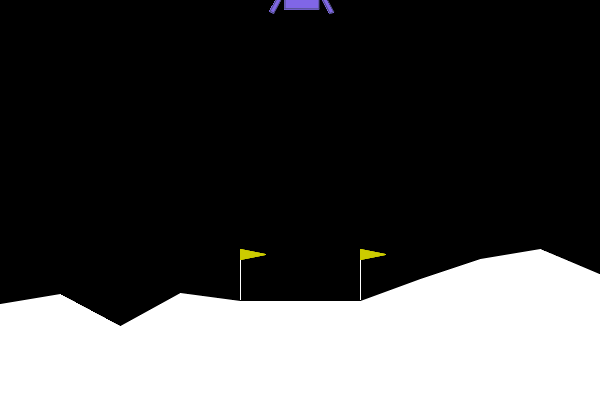

In [ ]:
# TODO === 1.3 Record a random policy video ===

def random_policy(obs):
    return video_env.action_space.sample()

video_path = "random_policy_lander.gif"

random_video_return = record_video(
    env=video_env,
    policy=random_policy,
    out_directory=video_path,
    fps=30,
    random_action=False,   
    max_steps=1000
)

print("Random policy video return:", random_video_return)

from IPython.display import Image, display
display(Image(filename=video_path))


## 2. A small finite MDP

To practice Iterative Policy Evaluation and Policy Iteration, we will use a small tabular MDP

In [ ]:
import numpy as np

def build_gridworld_mdp():
    # Grid size
    n_rows, n_cols = 4, 4
    n_states = n_rows * n_cols

    # Actions: 0=UP, 1=RIGHT, 2=DOWN, 3=LEFT
    n_actions = 4

    P = np.zeros((n_states, n_actions, n_states), dtype=np.float64)

    R = np.zeros((n_states, n_actions, n_states), dtype=np.float64)

    # Terminal states: top-left and bottom-right
    terminal_states = [0, n_states - 1]

    def to_state(r, c):
        return r * n_cols + c

    def to_rc(s):
        return divmod(s, n_cols)

    # Dynamics
    for s in range(n_states):
        r, c = to_rc(s)

        if s in terminal_states:
            for a in range(n_actions):
                P[s, a, s] = 1.0
                R[s, a, s] = 0.0
            continue

        for a in range(n_actions):
            nr, nc = r, c

            if a == 0:      # UP
                nr = max(r - 1, 0)
            elif a == 1:    # RIGHT
                nc = min(c + 1, n_cols - 1)
            elif a == 2:    # DOWN
                nr = min(r + 1, n_rows - 1)
            elif a == 3:    # LEFT
                nc = max(c - 1, 0)

            s_next = to_state(nr, nc)

            # Deterministic transition
            P[s, a, s_next] = 1.0

            # Step cost (standard): -1 per move
            R[s, a, s_next] = -1.0

    return n_states, n_actions, P, R, terminal_states


n_states, n_actions, P, R, terminal_states = build_gridworld_mdp()
print("Gridworld: n_states =", n_states, "| n_actions =", n_actions)
print("Terminal states:", terminal_states)


Gridworld: n_states = 16 | n_actions = 4
Terminal states: [0, 15]


### 2.1 Policy representation and Iterative Policy Evaluation

We represent a policy $\pi(a \mid s)$ as a 2D NumPy array of shape `[n_states, n_actions]`,
where each row is a probability distribution over actions in that state.

**Tasks:**

1. Define an **initial policy** that is **uniform over all actions** in non-terminal states.
2. Implement **Iterative Policy Evaluation**:

   $$V_{k+1}(s) = \sum_a \pi(a\mid s) \sum_{s'} P(s' \mid s, a) \left[R(s,a,s') + \gamma V_k(s') \right]$$

   Stop when the maximum change `delta` over all states is below a small threshold `theta`.

In [ ]:
# Discount factor for gridworld
gamma_grid = 1.0

# TODO 2.1: Define an initial uniform policy over actions (for non-terminal states)
n_states, n_actions, _ = P.shape
policy = np.ones((n_states, n_actions), dtype=np.float32) / n_actions

for s in terminal_states:
    policy[s, :] = 0.0


def iterative_policy_evaluation(policy, P, R, gamma=1.0, theta=1e-8):
    n_states, n_actions, _ = P.shape
    V = np.zeros(n_states, dtype=np.float32)

    while True:
        delta = 0.0
        V_new = V.copy()

        for s in range(n_states):
            if s in terminal_states:
                V_new[s] = 0.0
                continue

            v_s = 0.0
            for a in range(n_actions):
                v_s += policy[s, a] * np.sum(
                    P[s, a, :] * (R[s, a, :] + gamma * V)
                )

            V_new[s] = v_s
            delta = max(delta, float(abs(V_new[s] - V[s])))

        V = V_new

        if delta < theta:
            break

    return V


V_pi = iterative_policy_evaluation(policy, P, R, gamma=gamma_grid, theta=1e-8)
print("Value function under uniform policy (reshaped 4x4):")
print(V_pi.reshape(4, 4))


Value function under uniform policy (reshaped 4x4):
[[  0.       -13.999992 -19.999989 -21.999989]
 [-13.999992 -17.99999  -19.999989 -19.999989]
 [-19.999989 -19.999989 -17.99999  -13.999992]
 [-21.999989 -19.999989 -13.999992   0.      ]]


### 2.2 Policy Improvement and Policy Iteration

We now implement:

1. **Policy Improvement**: given $V(s)$, compute a greedy policy:
   $$\pi_{\text{greedy}}(s) = \arg\max_a \sum_{s'} P(s' \mid s,a) \left[ R(s,a,s') + \gamma V(s') \right]$$

2. **Policy Iteration**: alternate between policy evaluation and policy improvement until the policy stops changing.

In [ ]:
def policy_improvement(V, P, R, gamma=1.0):
    n_states, n_actions, _ = P.shape
    new_policy = np.zeros((n_states, n_actions), dtype=np.float32)

    for s in range(n_states):
        if s in terminal_states:
            new_policy[s, :] = 0.0
            continue

        q_values = np.zeros(n_actions, dtype=np.float32)
        for a in range(n_actions):
            q_values[a] = np.sum(P[s, a, :] * (R[s, a, :] + gamma * V))

        best_a = int(np.argmax(q_values))
        new_policy[s, best_a] = 1.0  # greedy deterministic

    return new_policy


def policy_iteration(P, R, gamma=1.0, theta=1e-8, max_iterations=1000):
    n_states, n_actions, _ = P.shape

    
    policy = np.ones((n_states, n_actions), dtype=np.float32) / n_actions
    for s in terminal_states:
        policy[s, :] = 0.0

    for it in range(max_iterations):

        V = iterative_policy_evaluation(policy, P, R, gamma=gamma, theta=theta)

        # Policy Improvement
        new_policy = policy_improvement(V, P, R, gamma=gamma)

     
        if np.array_equal(new_policy, policy):
            return policy, V

        policy = new_policy

    return policy, V


policy_star, V_star = policy_iteration(P, R, gamma=gamma_grid, theta=1e-8, max_iterations=1000)
print("Optimal value function (4x4):")
print(V_star.reshape(4, 4))
print("Optimal policy (action indices, 4x4):")
print(np.argmax(policy_star, axis=1).reshape(4, 4))


Optimal value function (4x4):
[[ 0. -1. -2. -3.]
 [-1. -2. -3. -2.]
 [-2. -3. -2. -1.]
 [-3. -2. -1.  0.]]
Optimal policy (action indices, 4x4):
[[0 3 3 2]
 [0 0 0 2]
 [0 0 1 2]
 [0 1 1 0]]


## 3. Tabular Q-Learning on LunarLander (with discretized state)

LunarLander has a **continuous state space**, so we cannot directly store a Q-table indexed by states.

We will:

1. **Discretize the 8-dimensional state vector** into a finite number of bins per dimension.
2. Maintain a **Q-table** `Q[discrete_state, action]`.
3. Implement **tabular Q-Learning**:

   $$Q(s,a) \leftarrow (1-\alpha) Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') \right]$$

4. Train a policy and compare its returns to the random baseline.

In [ ]:
obs_low = train_env.observation_space.low
obs_high = train_env.observation_space.high
print("Observation low:", obs_low)
print("Observation high:", obs_high)

n_actions_lander = train_env.action_space.n
print("Number of discrete actions:", n_actions_lander)

# bins per dimension (x, y, vx, vy, angle, ang_vel, leg1, leg2)
num_bins = np.array([6, 6, 8, 8, 8, 8, 2, 2], dtype=int)


# TODO 3.1: Create bin boundaries for each dimension
def create_bins(obs_low, obs_high, num_bins):
    """
    Returns a list 'bins' of length D.
    bins[i] is a 1D array of thresholds with length (num_bins[i]-1),
    suitable for np.digitize.
    """
    obs_low = np.array(obs_low, dtype=np.float64)
    obs_high = np.array(obs_high, dtype=np.float64)

    # Handle +/- inf in bounds by using reasonable clipping ranges
    # (These are standard practical ranges for LunarLander features)
    clip_low  = np.array([-0.8,  0.0, -1.2, -1.8, -1.2, -2.5, 0.0, 0.0], dtype=np.float64)
    clip_high = np.array([ 0.8,  1.4,  1.2,  1.8,  1.2,  2.5, 1.0, 1.0], dtype=np.float64)


    low = np.where(np.isfinite(obs_low), obs_low, clip_low)
    high = np.where(np.isfinite(obs_high), obs_high, clip_high)

    
    low = np.maximum(low, clip_low)
    high = np.minimum(high, clip_high)

    bins = []
    for i, b in enumerate(num_bins):
        b = int(b)
        if b <= 1:
            bins.append(np.array([], dtype=np.float64))
            continue

        # internal thresholds (exclude endpoints) => length b-1
        edges = np.linspace(low[i], high[i], b + 1)[1:-1]
        bins.append(edges.astype(np.float64))

    return bins


bins = create_bins(obs_low, obs_high, num_bins)

# TODO 3.2: Discretize a continuous observation into a tuple of indices
def discretize_observation(obs, bins):
    """
    obs: shape (D,)
    bins: list of D arrays, each of length (num_bins[d]-1)
    returns: tuple of D ints, each in [0, num_bins[d]-1]
    """
    obs = np.array(obs, dtype=np.float64)
    discrete = []

    for i, thresholds in enumerate(bins):
        # np.digitize gives an index in [0..len(thresholds)]
        idx = int(np.digitize(obs[i], thresholds, right=False))
        discrete.append(idx)

    return tuple(discrete)



test_state = discretize_observation(obs, bins)
print("Example discrete state:", test_state)
print("Discrete state dimensions:", len(test_state))
print("Max allowed per dim:", (num_bins - 1))
print("State within range:", all(0 <= test_state[i] <= (num_bins[i]-1) for i in range(len(num_bins))))


Observation low: [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
Observation high: [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]
Number of discrete actions: 4
Example discrete state: (2, 5, 2, 3, 4, 4, 0, 0)
Discrete state dimensions: 8
Max allowed per dim: [5 5 7 7 7 7 1 1]
State within range: True


In [ ]:
import numpy as np

# =========================
# Hyperparameters
# =========================
alpha = 1          
gamma_q = 0.995
epsilon_start = 1.0
epsilon_end = 0.02
epsilon_decay = 0.9995
num_episodes = 12000
max_steps_per_episode = 1000

state_shape = tuple(num_bins)
q_table = np.zeros(state_shape + (n_actions_lander,), dtype=np.float32)


# =========================
# Epsilon-greedy policy
# =========================
def epsilon_greedy_action(q_table, state, epsilon, n_actions):
    if np.random.rand() < epsilon:
        return np.random.randint(n_actions)
    return int(np.argmax(q_table[state]))


# =========================
# Q-Learning (Tabular, with decaying alpha via visit counts)
# =========================
def q_learning_train(
    env, bins, num_bins,
    num_episodes=10000, max_steps=1000,
    alpha=1.0, gamma=0.995,
    epsilon_start=1.0, epsilon_end=0.02, epsilon_decay=0.9995
):
    n_actions = env.action_space.n
    state_shape = tuple(num_bins)

    q_table = np.full(state_shape + (n_actions,), 1.0, dtype=np.float32)

   
    visit_counts = np.zeros(state_shape + (n_actions,), dtype=np.int32)

    episode_returns = []
    epsilon = float(epsilon_start)

    for ep in range(num_episodes):
        obs, info = env.reset()
        state = discretize_observation(obs, bins)

        total_reward = 0.0
        terminated = False
        truncated = False

        for t in range(max_steps):
            if terminated or truncated:
                break

            action = epsilon_greedy_action(q_table, state, epsilon, n_actions)

            next_obs, reward, terminated, truncated, info = env.step(action)
            next_state = discretize_observation(next_obs, bins)

            done_bootstrap = 0.0 if terminated else 1.0
            target = float(reward) + gamma * done_bootstrap * float(np.max(q_table[next_state]))

            
            idx = state + (action,)
            visit_counts[idx] += 1
            effective_alpha = alpha / np.sqrt(visit_counts[idx])

            if ep >= 8000:
                effective_alpha = min(effective_alpha, 0.05)


            # update
            q_table[idx] = (1.0 - effective_alpha) * q_table[idx] + effective_alpha * target

            state = next_state
            total_reward += float(reward)

        episode_returns.append(total_reward)

        # epsilon schedule
        if ep >= 8000:
            epsilon = epsilon_end
        else:
            epsilon = max(epsilon_end, epsilon * epsilon_decay)


       
        if (ep + 1) % 200 == 0:
            last = episode_returns[-200:]
            print(
                f"Episode {ep+1}/{num_episodes} | "
                f"eps={epsilon:.3f} | "
                f"mean_return(last200)={np.mean(last):.2f}"
            )

    return q_table, episode_returns


# =========================
# Train
# =========================
q_table, episode_returns = q_learning_train(
    train_env, bins, num_bins,
    num_episodes=num_episodes,
    max_steps=max_steps_per_episode,
    alpha=alpha,
    gamma=gamma_q,
    epsilon_start=epsilon_start,
    epsilon_end=epsilon_end,
    epsilon_decay=epsilon_decay,
)

Episode 200/12000 | eps=0.905 | mean_return(last200)=-166.60
Episode 400/12000 | eps=0.819 | mean_return(last200)=-137.76
Episode 600/12000 | eps=0.741 | mean_return(last200)=-127.67
Episode 800/12000 | eps=0.670 | mean_return(last200)=-120.86
Episode 1000/12000 | eps=0.606 | mean_return(last200)=-113.72
Episode 1200/12000 | eps=0.549 | mean_return(last200)=-124.38
Episode 1400/12000 | eps=0.496 | mean_return(last200)=-92.95
Episode 1600/12000 | eps=0.449 | mean_return(last200)=-121.15
Episode 1800/12000 | eps=0.406 | mean_return(last200)=-95.29
Episode 2000/12000 | eps=0.368 | mean_return(last200)=-101.22
Episode 2200/12000 | eps=0.333 | mean_return(last200)=-101.12
Episode 2400/12000 | eps=0.301 | mean_return(last200)=-111.57
Episode 2600/12000 | eps=0.272 | mean_return(last200)=-124.77
Episode 2800/12000 | eps=0.247 | mean_return(last200)=-120.99
Episode 3000/12000 | eps=0.223 | mean_return(last200)=-120.76
Episode 3200/12000 | eps=0.202 | mean_return(last200)=-106.44
Episode 3400/1

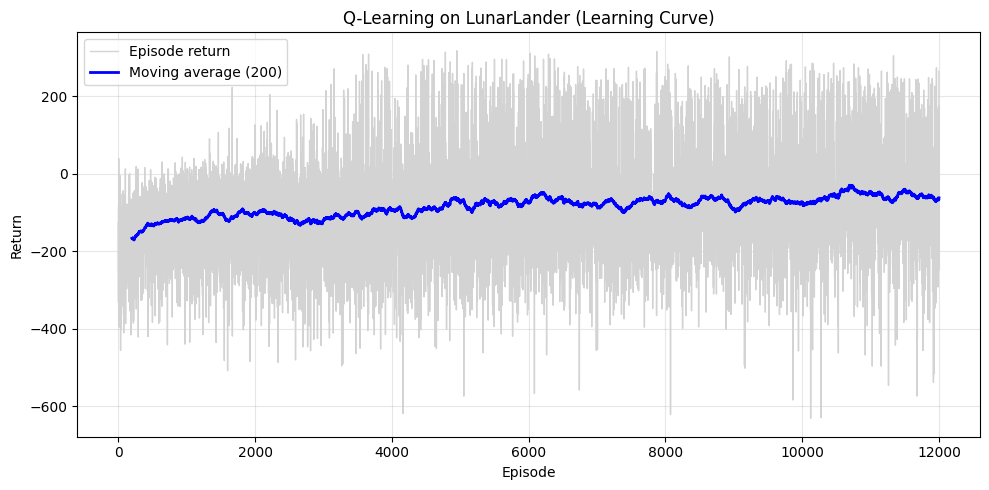

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# TODO 3.5: Plot learning curve
# =========================

def plot_learning_curve(episode_returns, window=200):
    """
    episode_returns: list of total reward per episode
    window: moving average window size
    """
    returns = np.array(episode_returns, dtype=np.float32)

    # Moving average
    if len(returns) >= window:
        kernel = np.ones(window) / window
        moving_avg = np.convolve(returns, kernel, mode="valid")
        x_avg = np.arange(window - 1, len(returns))
    else:
        moving_avg = returns
        x_avg = np.arange(len(returns))

    plt.figure(figsize=(10, 5))
    plt.plot(returns, color="lightgray", linewidth=1, label="Episode return")
    plt.plot(x_avg, moving_avg, color="blue", linewidth=2, label=f"Moving average ({window})")

    plt.xlabel("Episode")
    plt.ylabel("Return")
    plt.title("Q-Learning on LunarLander (Learning Curve)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# =========================
# Call after training
# =========================
plot_learning_curve(episode_returns, window=200)


In [12]:
# TODO 3.6: deterministic greedy policy from q_table
def q_table_greedy_policy(q_table, bins):
    """
    Returns a policy function policy(obs) -> action
    that discretizes the observation and picks argmax_a Q(s,a).
    Uses random tie-breaking to avoid argmax bias.
    """
    n_actions = q_table.shape[-1]

    def policy(obs):
        state = discretize_observation(obs, bins)  # tuple indices
        q = q_table[state]                         # shape (n_actions,)
        max_q = np.max(q)
        best_actions = np.flatnonzero(q == max_q)  # tie-breaking
        return int(np.random.choice(best_actions))

    return policy


Using env_id='LunarLander-v3', render_mode='rgb_array'
Trained policy video return: -224.54664392402265


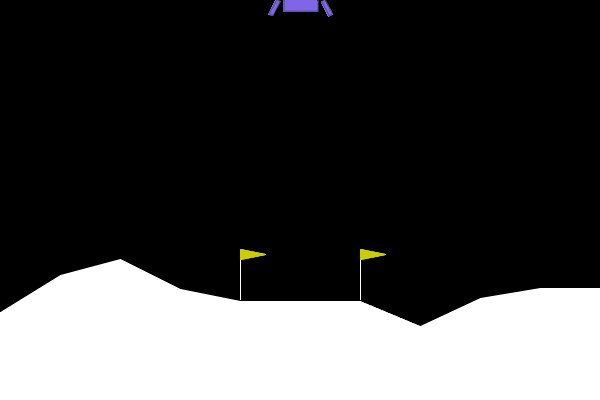

In [17]:
# TODO === 3.7 Record a trained policy video ===
import os
from IPython.display import Image, display

# 1) greedy policy از Q-table
trained_policy = q_table_greedy_policy(q_table, bins)

# 2) env مخصوص رندر (rgb_array)
video_env = make_lander_env(render_mode="rgb_array")

# 3) ضبط به صورت GIF (بدون نیاز به ffmpeg)
os.makedirs("videos", exist_ok=True)
video_path = "videos/trained_policy.gif"

trained_return = record_video(
    env=video_env,
    policy=trained_policy,
    out_directory=video_path,
    fps=30,
    random_action=False,
    max_steps=1600,
)

video_env.close()

print("Trained policy video return:", trained_return)
display(Image(filename=video_path))
